# AgroLens — Plant Disease Classifier Training Notebook

Trains a MobileNetV2-based leaf disease classifier on the PlantVillage dataset,
evaluates it, saves it, and includes a real-time image-upload inference tester.

**How to use this notebook:**
1. Download the PlantVillage dataset from Kaggle and unzip it somewhere on your machine.
2. In the **Configuration** cell below, set `DATASET_DIR` to the folder path.
3. Run all cells top to bottom (`Kernel > Restart & Run All`).
4. Use the last section to upload any leaf photo and see a live prediction.

This notebook trains on your **laptop/Colab GPU**, not on the ESP32-CAM. The ESP32-CAM only
runs the final quantized model (that comes later, in the TFLite Micro conversion step).


## 0. Install & import dependencies

In [1]:
# Run this once. Restart the kernel if TensorFlow was just installed.
# !pip install tensorflow scikit-learn matplotlib seaborn split-folders pillow ipywidgets --quiet


In [2]:
import os
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


C:\Users\KIIT0001\AppData\Roaming\Python\Python311\site-packages\google\api_core\_python_version_support.py:266: FutureWarning: You are using a Python version (3.11.9) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


TensorFlow version: 2.21.0
GPU available: []


## 1. Configuration — EDIT THIS CELL

This notebook is configured for the **abdallahalidev/plantvillage-dataset** Kaggle dataset
(38 classes, ~54,000 images: `https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset`).

After downloading and unzipping, this dataset's folder structure looks like:

```
PlantVillage/
    color/
        Tomato___Bacterial_spot/
        Tomato___Late_blight/
        Tomato___healthy/
        Apple___Cedar_apple_rust/
        ...  (38 class folders total, triple-underscore names)
    grayscale/
        ... (same classes, grayscale versions — not used here)
    segmented/
        ... (same classes, background-removed versions — not used here)
```

Set `DATASET_DIR` to the **outer** unzipped folder (the one containing `color/`,
`grayscale/`, `segmented/`) — the cell below automatically finds and uses the `color/`
subfolder, since that's the version closest to what the ESP32-CAM camera will actually
capture. If your download doesn't have this `color/`/`grayscale/`/`segmented/` split,
it will just use `DATASET_DIR` directly — no changes needed either way.

If you only want tomato classes (recommended — see project notes), set
`FILTER_KEYWORD = "Tomato"`. Set it to `None` to use every class in the folder.


In [3]:
# ============================================================
# EDIT THESE VALUES
# ============================================================

DATASET_DIR = r"C:\Major\archive (1)\plantvillage dataset"   # <-- CHANGE THIS to your unzipped dataset folder
                                               # (the outer folder containing color/grayscale/segmented,
                                               # or the folder containing class subfolders directly)

FILTER_KEYWORD = "Tomato"   # keep only classes whose folder name contains this string.
                             # Set to None to use ALL classes in DATASET_DIR.

IMG_SIZE = (96, 96)         # 96x96 keeps the model small enough for later TFLite Micro conversion.
                             # Use 224x224 only if you plan to prune/quantize aggressively.

BATCH_SIZE = 32
EPOCHS = 15
SEED = 42

WORK_DIR = "./agrolens_work"        # scratch folder this notebook creates
FILTERED_DIR = os.path.join(WORK_DIR, "filtered_dataset")
SPLIT_DIR = os.path.join(WORK_DIR, "split_dataset")
MODEL_SAVE_PATH = os.path.join(WORK_DIR, "agrolens_model.keras")
MODEL_SAVEDMODEL_PATH = os.path.join(WORK_DIR, "agrolens_savedmodel")

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

os.makedirs(WORK_DIR, exist_ok=True)
print("Config set. Dataset dir:", DATASET_DIR)


Config set. Dataset dir: C:\Major\archive (1)\plantvillage dataset


## 2. Filter to selected classes (optional)

First auto-detects whether `DATASET_DIR` is the outer folder (containing `color/`,
`grayscale/`, `segmented/` — the abdallahalidev dataset layout) or already the folder of
class subfolders directly (the emmarex mirror layout). Then, if `FILTER_KEYWORD` is set,
copies only the matching class folders into a smaller working directory — keeps training
fast and keeps the final model small enough for the ESP32-CAM's memory budget.


In [4]:
assert os.path.isdir(DATASET_DIR), f"DATASET_DIR does not exist: {DATASET_DIR}. Fix the path in the config cell above."

# Auto-detect the abdallahalidev color/grayscale/segmented layout
if os.path.isdir(os.path.join(DATASET_DIR, "color")):
    SOURCE_DIR = os.path.join(DATASET_DIR, "color")
    print("Detected color/grayscale/segmented layout — using the 'color' subfolder.")
else:
    SOURCE_DIR = DATASET_DIR
    print("Using DATASET_DIR directly as the class-folder root.")

all_classes = sorted([d for d in os.listdir(SOURCE_DIR) if os.path.isdir(os.path.join(SOURCE_DIR, d))])
print(f"Found {len(all_classes)} classes in dataset folder.")

if FILTER_KEYWORD:
    selected_classes = [c for c in all_classes if FILTER_KEYWORD.lower() in c.lower()]
else:
    selected_classes = all_classes

assert len(selected_classes) > 0, "No classes matched your FILTER_KEYWORD. Check spelling or set it to None."

print(f"Using {len(selected_classes)} classes:")
for c in selected_classes:
    print("  -", c)

if os.path.exists(FILTERED_DIR):
    shutil.rmtree(FILTERED_DIR)
os.makedirs(FILTERED_DIR, exist_ok=True)

for c in selected_classes:
    src = os.path.join(SOURCE_DIR, c)
    dst = os.path.join(FILTERED_DIR, c)
    shutil.copytree(src, dst)

print("Filtered dataset ready at:", FILTERED_DIR)


Detected color/grayscale/segmented layout — using the 'color' subfolder.
Found 38 classes in dataset folder.
Using 10 classes:
  - Tomato___Bacterial_spot
  - Tomato___Early_blight
  - Tomato___Late_blight
  - Tomato___Leaf_Mold
  - Tomato___Septoria_leaf_spot
  - Tomato___Spider_mites Two-spotted_spider_mite
  - Tomato___Target_Spot
  - Tomato___Tomato_Yellow_Leaf_Curl_Virus
  - Tomato___Tomato_mosaic_virus
  - Tomato___healthy


Filtered dataset ready at: ./agrolens_work\filtered_dataset


## 3. Clean corrupt / unreadable images

In [5]:
from PIL import Image

def clean_dataset(root_dir):
    removed = 0
    for subdir, _, files in os.walk(root_dir):
        for f in files:
            path = os.path.join(subdir, f)
            try:
                img = Image.open(path)
                img.verify()
            except Exception:
                os.remove(path)
                removed += 1
    return removed

removed_count = clean_dataset(FILTERED_DIR)
print(f"Removed {removed_count} corrupt/unreadable files.")


Removed 0 corrupt/unreadable files.


## 4. Train / Validation / Test split

Stratified 70/15/15 split so every class is proportionally represented in each split.


In [6]:
def split_dataset(source_dir, dest_dir, split_ratio=(0.7, 0.15, 0.15), seed=SEED):
    assert abs(sum(split_ratio) - 1.0) < 1e-6
    if os.path.exists(dest_dir):
        shutil.rmtree(dest_dir)

    classes = sorted([d for d in os.listdir(source_dir) if os.path.isdir(os.path.join(source_dir, d))])
    rng = random.Random(seed)

    for split_name in ["train", "val", "test"]:
        for c in classes:
            os.makedirs(os.path.join(dest_dir, split_name, c), exist_ok=True)

    for c in classes:
        files = os.listdir(os.path.join(source_dir, c))
        rng.shuffle(files)
        n = len(files)
        n_train = int(n * split_ratio[0])
        n_val = int(n * split_ratio[1])

        train_files = files[:n_train]
        val_files = files[n_train:n_train + n_val]
        test_files = files[n_train + n_val:]

        for f in train_files:
            shutil.copy(os.path.join(source_dir, c, f), os.path.join(dest_dir, "train", c, f))
        for f in val_files:
            shutil.copy(os.path.join(source_dir, c, f), os.path.join(dest_dir, "val", c, f))
        for f in test_files:
            shutil.copy(os.path.join(source_dir, c, f), os.path.join(dest_dir, "test", c, f))

    return classes

class_names = split_dataset(FILTERED_DIR, SPLIT_DIR)
print("Classes:", class_names)

for split_name in ["train", "val", "test"]:
    total = sum(len(os.listdir(os.path.join(SPLIT_DIR, split_name, c))) for c in class_names)
    print(f"{split_name}: {total} images")


Classes: ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']
train: 12707 images
val: 2719 images
test: 2734 images


## 5. Load data + augmentation

Augmentation is applied only to the training set. **Pixels stay in 0-255 here**: the rescaling
to [-1, 1] (what MobileNetV2's ImageNet weights expect) is now the first layer *inside* the model,
so the ESP32 only ever has to send raw pixels.


In [7]:
train_dir = os.path.join(SPLIT_DIR, "train")
val_dir = os.path.join(SPLIT_DIR, "val")
test_dir = os.path.join(SPLIT_DIR, "test")

train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=SEED, label_mode="categorical"
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=SEED, label_mode="categorical"
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=BATCH_SIZE, seed=SEED, label_mode="categorical", shuffle=False
)

class_names = train_ds_raw.class_names
num_classes = len(class_names)
print("Class names (index order used by the model):", class_names)

data_augmentation = tf.keras.Sequential([
    layers.RandomRotation(0.06),       # ~20 degrees
    layers.RandomBrightness(0.15),
    layers.RandomContrast(0.15),
    layers.RandomFlip("horizontal"),
    layers.RandomZoom(0.1),
])

def prep_train(ds):
    ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

def prep_eval(ds):
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = prep_train(train_ds_raw)
val_ds = prep_eval(val_ds)
test_ds = prep_eval(test_ds)


Found 12707 files belonging to 10 classes.
Found 2719 files belonging to 10 classes.
Found 2734 files belonging to 10 classes.
Class names (index order used by the model): ['Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Tomato___Tomato_mosaic_virus', 'Tomato___healthy']


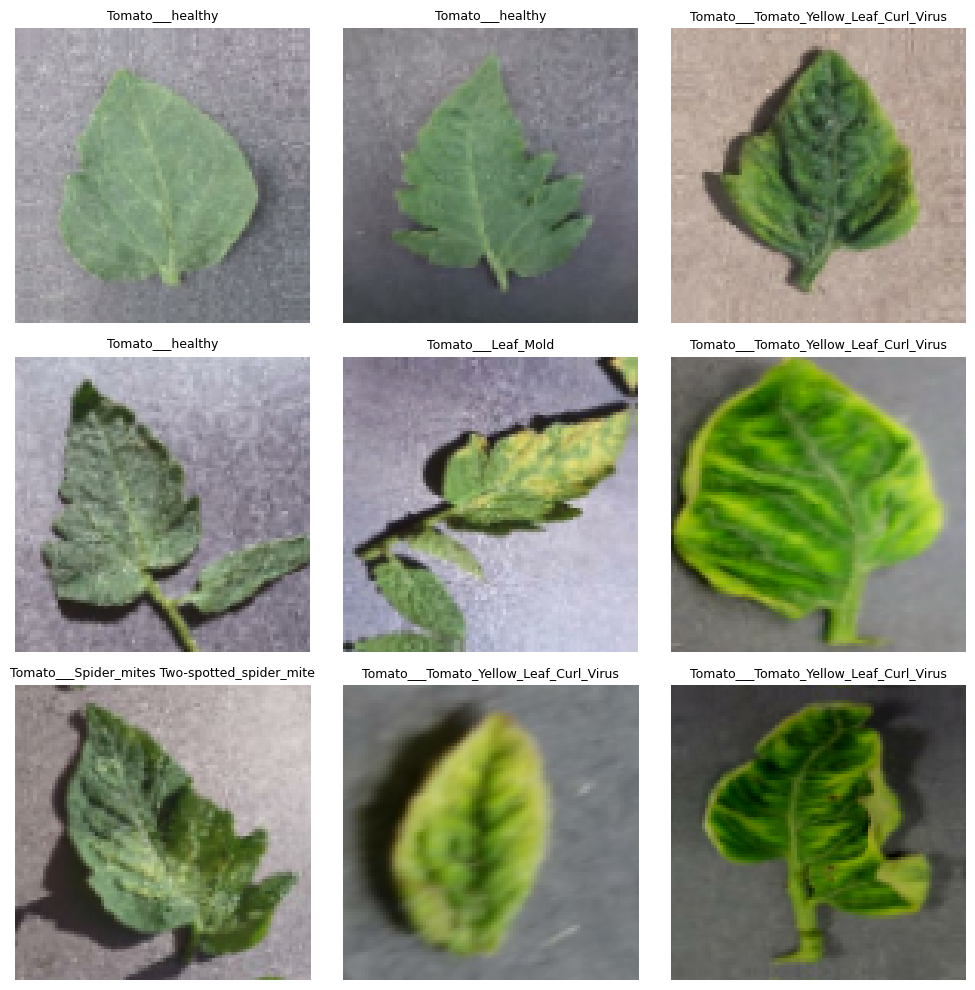

In [8]:
# Quick sanity check: visualize a batch of augmented training images
plt.figure(figsize=(10, 10))
for images, labels in train_ds_raw.take(1):
    aug_images = data_augmentation(images, training=True)
    for i in range(min(9, images.shape[0])):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(aug_images[i].numpy().astype("uint8"))
        plt.title(class_names[int(tf.argmax(labels[i]))], fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()


## 6. Model architecture — MobileNetV2 transfer learning

MobileNetV2 pretrained on ImageNet is used as a frozen feature extractor, with a small
classification head trained on top. This backbone is specifically chosen because it
quantizes well and is small enough for ESP32-CAM after TFLite Micro conversion.


In [9]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,),
    include_top=False,
    weights="imagenet",
    alpha=0.35,   # width multiplier — smaller alpha = smaller/faster model, needed for ESP32-CAM
)
base_model.trainable = False   # freeze backbone for initial training

model = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    layers.Rescaling(1./127.5, offset=-1),   # 0-255 -> [-1, 1] (MobileNetV2 preprocessing, now inside the model)
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(num_classes, activation="softmax"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_0.35_96             │ (None, 3, 3, 1280)     │       410,208 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 492,842 (1.88 MB)

 Trainable params: 82,634 (322.79 KB)

 Non-trainable params: 410,208 (1.56 MB)

## 7. Training

Trains the classification head first (backbone frozen), then fine-tunes the last 20 backbone
layers at a low learning rate. **BatchNorm layers stay frozen** during fine-tuning (unfreezing them
caused the accuracy collapse in the first run), and the better of the two models is kept.


In [10]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)


Epoch 1/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 53s 122ms/step - accuracy: 0.7077 - loss: 0.8755 - val_accuracy: 0.8128 - val_loss: 0.5875 - learning_rate: 0.0010
Epoch 2/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 31s 77ms/step - accuracy: 0.8214 - loss: 0.5307 - val_accuracy: 0.8396 - val_loss: 0.4658 - learning_rate: 0.0010
Epoch 3/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 31s 77ms/step - accuracy: 0.8442 - loss: 0.4671 - val_accuracy: 0.8444 - val_loss: 0.4650 - learning_rate: 0.0010
Epoch 4/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 29s 74ms/step - accuracy: 0.8487 - loss: 0.4315 - val_accuracy: 0.8216 - val_loss: 0.5158 - learning_rate: 0.0010
Epoch 5/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 30s 75ms/step - accuracy: 0.8593 - loss: 0.4064 - val_accuracy: 0.8371 - val_loss: 0.4696 - learning_rate: 0.0010
Epoch 6/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 30s 76ms/step - accuracy: 0.8682 - loss: 0.3823 - val_accuracy: 0.8584 - val_loss: 0.4099 - learning_rate: 5.0000e-04
Epoch 7/15
398/398 ━━━━━━━━━━━━━━━━━━━━ 33s 82ms/step - accuracy: 0.876

In [11]:
# Fine-tuning with BatchNorm layers kept frozen
pre_loss, pre_acc = model.evaluate(val_ds, verbose=0)
pre_weights = model.get_weights()
print(f"Val accuracy before fine-tuning: {pre_acc:.4f}")

base_model.trainable = True
fine_tune_at = len(base_model.layers) - 20
for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

fine_tune_epochs = 5
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=fine_tune_epochs,
    callbacks=callbacks,
)

post_loss, post_acc = model.evaluate(val_ds, verbose=0)
print(f"Val accuracy after fine-tuning:  {post_acc:.4f}")
if post_acc < pre_acc:
    model.set_weights(pre_weights)
    print("Fine-tuning did not help -> restored the pre-fine-tuning weights.")
else:
    print("Fine-tuning helped -> keeping fine-tuned weights.")


Val accuracy before fine-tuning: 0.8713
Epoch 1/5
398/398 ━━━━━━━━━━━━━━━━━━━━ 36s 81ms/step - accuracy: 0.8942 - loss: 0.3110 - val_accuracy: 0.8716 - val_loss: 0.3673 - learning_rate: 1.0000e-05
Epoch 2/5
398/398 ━━━━━━━━━━━━━━━━━━━━ 32s 80ms/step - accuracy: 0.8938 - loss: 0.3020 - val_accuracy: 0.8617 - val_loss: 0.3992 - learning_rate: 1.0000e-05
Epoch 3/5
398/398 ━━━━━━━━━━━━━━━━━━━━ 37s 92ms/step - accuracy: 0.9004 - loss: 0.2889 - val_accuracy: 0.8672 - val_loss: 0.3783 - learning_rate: 5.0000e-06
Epoch 4/5
398/398 ━━━━━━━━━━━━━━━━━━━━ 32s 80ms/step - accuracy: 0.9067 - loss: 0.2774 - val_accuracy: 0.8680 - val_loss: 0.3695 - learning_rate: 5.0000e-06
Epoch 5/5
398/398 ━━━━━━━━━━━━━━━━━━━━ 31s 77ms/step - accuracy: 0.9023 - loss: 0.2876 - val_accuracy: 0.8727 - val_loss: 0.3422 - learning_rate: 2.5000e-06
Val accuracy after fine-tuning:  0.8727
Fine-tuning helped -> keeping fine-tuned weights.


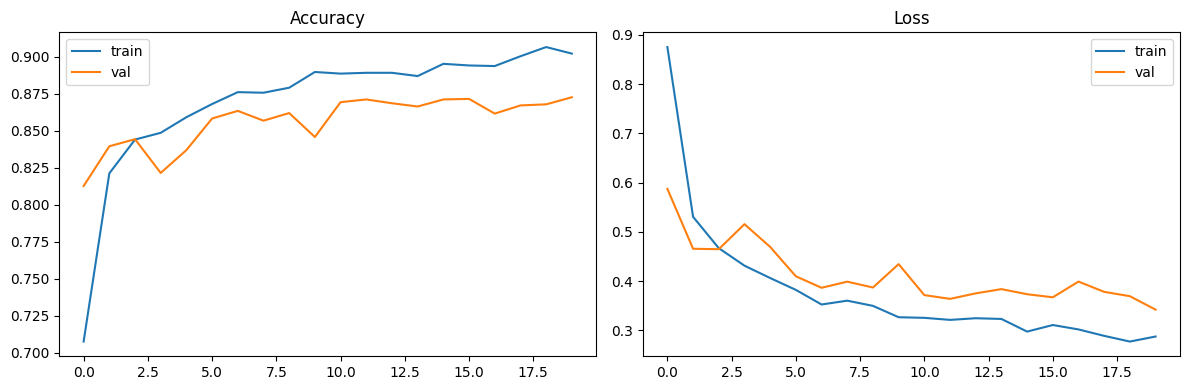

In [12]:
# Plot training curves
def plot_history(h1, h2=None):
    acc = h1.history["accuracy"]
    val_acc = h1.history["val_accuracy"]
    loss = h1.history["loss"]
    val_loss = h1.history["val_loss"]

    if h2 is not None:
        acc += h2.history["accuracy"]
        val_acc += h2.history["val_accuracy"]
        loss += h2.history["loss"]
        val_loss += h2.history["val_loss"]

    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(acc, label="train")
    plt.plot(val_acc, label="val")
    plt.title("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(loss, label="train")
    plt.plot(val_loss, label="val")
    plt.title("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

plot_history(history, history_fine if 'history_fine' in dir() else None)


## 8. Evaluation on the held-out test set

Reports accuracy, precision, recall, F1-score (per class and macro-averaged), and a
confusion matrix — the metrics your proposal commits to reporting.


In [13]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

y_true = []
y_pred = []
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_true.extend(np.argmax(labels.numpy(), axis=1))
    y_pred.extend(np.argmax(preds, axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("\nClassification report:")
print(classification_report(y_true, y_pred, target_names=class_names))

precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")
print(f"Macro Precision: {precision:.4f}  Macro Recall: {recall:.4f}  Macro F1: {f1:.4f}")


86/86 ━━━━━━━━━━━━━━━━━━━━ 8s 92ms/step - accuracy: 0.8778 - loss: 0.3498
Test accuracy: 0.8778
Test loss: 0.3498

Classification report:
                                               precision    recall  f1-score   support

                      Tomato___Bacterial_spot       0.87      0.94      0.90       320
                        Tomato___Early_blight       0.78      0.65      0.71       150
                         Tomato___Late_blight       0.93      0.88      0.90       287
                           Tomato___Leaf_Mold       0.99      0.75      0.85       144
                  Tomato___Septoria_leaf_spot       0.84      0.85      0.84       267
Tomato___Spider_mites Two-spotted_spider_mite       0.79      0.83      0.81       252
                         Tomato___Target_Spot       0.73      0.71      0.72       212
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       0.99      0.95      0.97       805
                 Tomato___Tomato_mosaic_virus       0.79      0.95      0.86  

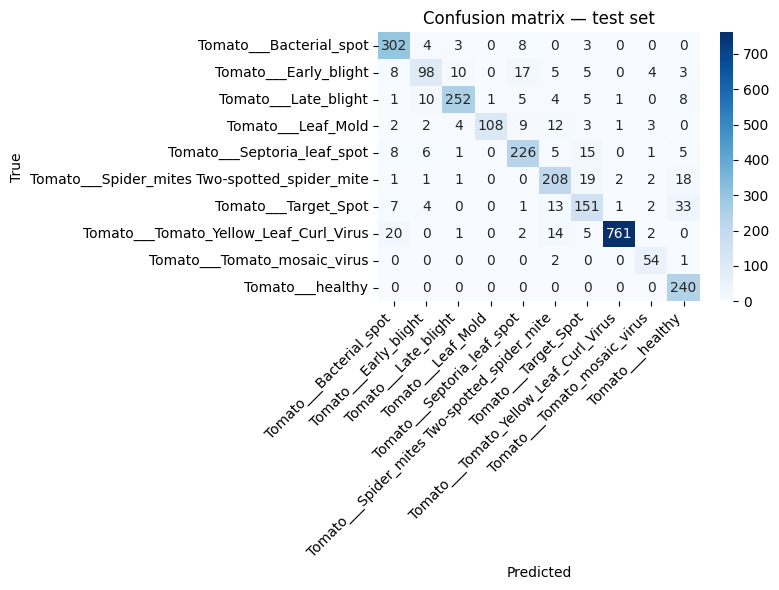

In [14]:
# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion matrix — test set")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## 9. Save the trained model

Saves both a `.keras` file (for reuse in this notebook / further training) and a
TensorFlow SavedModel folder (needed later for TFLite / TFLite Micro conversion in the
next stage of the project).


In [15]:
model.save(MODEL_SAVE_PATH)
model.export(MODEL_SAVEDMODEL_PATH)

with open(os.path.join(WORK_DIR, "class_names.txt"), "w") as f:
    for c in class_names:
        f.write(c + "\n")

print("Saved model to:", MODEL_SAVE_PATH)
print("Saved SavedModel export to:", MODEL_SAVEDMODEL_PATH)
print("Saved class names to:", os.path.join(WORK_DIR, "class_names.txt"))
print("\nNext: sections 11-13 below convert this model to INT8 TFLite for the ESP32-S3.")


INFO:tensorflow:Assets written to: ./agrolens_work\agrolens_savedmodel\assets


INFO:tensorflow:Assets written to: ./agrolens_work\agrolens_savedmodel\assets


Saved artifact at './agrolens_work\agrolens_savedmodel'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 96, 96, 3), dtype=tf.float32, name='keras_tensor_160')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  2550513856976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513857744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513858704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513858320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513857552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513857936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513860240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513859856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513860432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513859472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  255051384718

## 10. Real-time inference — upload an image and get a live prediction

Run the cell below, click "Upload", pick any leaf photo from your computer, and the
model's prediction (disease name + confidence) will display immediately below it.
This simulates what the ESP32-CAM will do in the field, just running here on your PC.


In [16]:
import ipywidgets as widgets
from IPython.display import display, clear_output
from PIL import Image
import io

uploader = widgets.FileUpload(accept="image/*", multiple=False, description="Upload leaf photo")
output = widgets.Output()

def predict_image(img: Image.Image):
    img_resized = img.convert("RGB").resize(IMG_SIZE)
    arr = np.array(img_resized).astype("float32")   # raw 0-255; scaling is inside the model
    arr = np.expand_dims(arr, axis=0)
    preds = model.predict(arr, verbose=0)[0]
    top_idx = int(np.argmax(preds))
    return class_names[top_idx], float(preds[top_idx]), preds

def on_upload_change(change):
    with output:
        clear_output()
        if not uploader.value:
            return
        uploaded_file = list(uploader.value.values())[0] if isinstance(uploader.value, dict) else uploader.value[0]
        content = uploaded_file["content"] if isinstance(uploaded_file, dict) else uploaded_file.content
        img = Image.open(io.BytesIO(content))

        predicted_class, confidence, all_preds = predict_image(img)

        plt.figure(figsize=(4, 4))
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"{predicted_class}\n{confidence*100:.1f}% confidence", fontsize=11)
        plt.show()

        print("Full class probabilities:")
        for cname, p in sorted(zip(class_names, all_preds), key=lambda x: -x[1]):
            print(f"  {cname:35s} {p*100:5.1f}%")

uploader.observe(on_upload_change, names="value")
display(uploader, output)


FileUpload(value=(), accept='image/*', description='Upload leaf photo')

Output()

### Notes

- If confidence is consistently low on real photographed leaves (as opposed to PlantVillage-style
  images), that is the **domain gap** — expected, and worth reporting honestly.
- Sections 11-13 below produce `agrolens.tflite`, verify it, and export `model_data.h` for the ESP32-S3 firmware.


## 11. Convert to INT8 TFLite

The representative dataset lets the converter measure typical value ranges per layer so it can pick good int8 scales.
It uses raw 0-255 images, because the rescaling is part of the model.

In [17]:
def rep_data():
    for imgs, _ in train_ds_raw.take(50):          # ~1600 raw 0-255 images
        for img in imgs:
            yield [np.expand_dims(img.numpy().astype("float32"), 0)]

conv = tf.lite.TFLiteConverter.from_keras_model(model)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
conv.representative_dataset = rep_data
conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
conv.inference_input_type = tf.int8
conv.inference_output_type = tf.int8
tflite_model = conv.convert()

TFLITE_PATH = os.path.join(WORK_DIR, "agrolens.tflite")
with open(TFLITE_PATH, "wb") as f:
    f.write(tflite_model)
print("Saved:", TFLITE_PATH, "| size (KB):", round(len(tflite_model) / 1024, 1))


INFO:tensorflow:Assets written to: C:\Users\KIIT0001\AppData\Local\Temp\tmpbxuna6uw\assets


INFO:tensorflow:Assets written to: C:\Users\KIIT0001\AppData\Local\Temp\tmpbxuna6uw\assets


Saved artifact at 'C:\Users\KIIT0001\AppData\Local\Temp\tmpbxuna6uw'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 96, 96, 3), dtype=tf.float32, name='keras_tensor_160')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  2550513856976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513857744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513858704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513858320: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513857552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513857936: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513860240: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513859856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513860432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2550513859472: TensorSpec(shape=(), dtype=tf.resource, name=None)
 

C:\Users\KIIT0001\AppData\Roaming\Python\Python311\site-packages\tensorflow\lite\python\convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Saved: ./agrolens_work\agrolens.tflite | size (KB): 710.3


## 12. Verify the INT8 model on the test set

Never flash a model you haven't tested. INT8 accuracy should be within a few percent of the float model.

In [18]:
interp = tf.lite.Interpreter(model_content=tflite_model)
interp.allocate_tensors()
inp = interp.get_input_details()[0]
out = interp.get_output_details()[0]
in_scale, in_zp = inp["quantization"]
print("Input  scale / zero_point:", in_scale, in_zp)
print("Output scale / zero_point:", out["quantization"])

test_raw = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=1, label_mode="categorical", shuffle=False
)

correct = total = 0
for imgs, labels in test_raw:
    q = np.clip(np.round(imgs.numpy() / in_scale + in_zp), -128, 127).astype(np.int8)
    interp.set_tensor(inp["index"], q)
    interp.invoke()
    pred = int(np.argmax(interp.get_tensor(out["index"])))
    correct += int(pred == int(np.argmax(labels.numpy())))
    total += 1

print(f"INT8 test accuracy: {correct / total:.4f}  (float model: {test_acc:.4f})")


Input  scale / zero_point: 1.0 -128
Output scale / zero_point: (0.00390625, -128)
Found 2734 files belonging to 10 classes.


C:\Users\KIIT0001\AppData\Roaming\Python\Python311\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


INT8 test accuracy: 0.8453  (float model: 0.8778)


## 13. Export for the ESP32-S3

Writes `model_data.h` (the model as a C byte array). Copy it into `esp_firmware/main/`.
The class order printed below must match `kClasses` in `main.cpp`.

In [19]:
data = open(TFLITE_PATH, "rb").read()
header_path = os.path.join(WORK_DIR, "model_data.h")
with open(header_path, "w") as f:
    f.write("#pragma once\n")
    f.write("alignas(16) const unsigned char agrolens_tflite[] = {\n")
    f.write(",".join(str(b) for b in data))
    f.write("\n};\nconst unsigned int agrolens_tflite_len = %d;\n" % len(data))
print("Wrote:", header_path)

print("\nClass order (index -> name), must match kClasses in main.cpp:")
for i, c in enumerate(class_names):
    print(f"  {i}: {c}")


Wrote: ./agrolens_work\model_data.h

Class order (index -> name), must match kClasses in main.cpp:
  0: Tomato___Bacterial_spot
  1: Tomato___Early_blight
  2: Tomato___Late_blight
  3: Tomato___Leaf_Mold
  4: Tomato___Septoria_leaf_spot
  5: Tomato___Spider_mites Two-spotted_spider_mite
  6: Tomato___Target_Spot
  7: Tomato___Tomato_Yellow_Leaf_Curl_Virus
  8: Tomato___Tomato_mosaic_virus
  9: Tomato___healthy
